### Alur Sistem:
1. **Audio WAV** (16 kHz Mono) $\rightarrow$ **MFCC 39D** (13 statis + 13 delta + 13 delta-delta).
2. **Pemotongan hening** dengan ambang batas energi 20 dB di bawah frame puncak.
3. **Pemodelan**:
   - **DTW**: pencarian medoid per vokal, penyejajaran jalur, dan perataan frame.
   - **Gaussian**: penggabungan frame per vokal, estimasi mean dan kovariansi penuh 39 x 39.
4. **Evaluasi**: pengujian pada data *Closed Recording*, *Closed Speakers*, dan *Open Speakers*.

### 1. Persiapan Pustaka & Modul
Seluruh pustaka pendukung (NumPy, Pandas, Matplotlib, Seaborn) dan modul sistem pada direktori `src/` dimuat pada tahap ini.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import soundfile as sf

REPO_ROOT = Path(".").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.preprocessing import (
    DEFAULT_CONFIG, PreprocessingConfig, load_audio, preprocess_audio,
    extract_mfcc39, process_audio_file, load_feature_file
)
from src.dataset_utils import (
    VOWELS, SPEAKERS, PARTITIONS, ALIASES,
    validate_dataset, load_dataset, discover_dataset
)
from src.silence import trim_silence
from src.dtw import dtw, backtrack
from src.dtw_templates import (
    average_template, build_templates, save_templates, load_templates
)
from src.dtw_predict import predict as predict_dtw
from src.gaussian import (
    fit_gaussian, nll, build_models, predict as predict_gaussian,
    save_models, load_models
)
from src import evaluation as ev

plt.rcParams['figure.dpi'] = 120
sns.set_theme(style="whitegrid", palette="muted")
print("Semua modul src/ berhasil diimpor.")


Semua modul src/ berhasil diimpor.


### 2. Validasi Integritas Berkas Audio
Pemeriksaan kondisi fisik seluruh berkas WAV pada direktori `data/` dilakukan sebelum model dilatih.
- Verifikasi kelengkapan 50 berkas internal (5 pembicara x 5 vokal x 2 take) dan 80 berkas dari 16 pembicara eksternal G03/Kel3, G04, G07, dan G09.
- Memastikan tidak ada berkas yang hilang, rusak, atau terduplikasi.

In [2]:
validation_report = validate_dataset("data")

print(f"Total Rekaman Internal Ditemukan  : {validation_report['actual_internal']}")
print(f"Total Rekaman Eksternal (Open)    : {validation_report['open_recordings']}")
print(f"Total Rekaman Decoded             : {validation_report['decoded_recordings']}")
print(f"Duplikasi                         : {len(validation_report['duplicate_audio'])} file")
print(f"File Hilang                       : {len(validation_report['missing'])} file")
print(f"Error Decoding                    : {len(validation_report['errors'])} error")
print(f"Inkonsistensi Format              : {validation_report['format_inconsistencies']}")

print(f"Pembicara Eksternal                : {validation_report['open_speakers']}")


Total Rekaman Internal Ditemukan  : 50
Total Rekaman Eksternal (Open)    : 80
Total Rekaman Decoded             : 130
Duplikasi                         : 0 file
File Hilang                       : 0 file
Error Decoding                    : 0 error
Inkonsistensi Format              : False
Pembicara Eksternal                : 16


### 3. Ringkasan Durasi & Jumlah Frame Audio
Berkas `features/metadata.csv` dibaca untuk menampilkan ringkasan statistik rekaman audio pada setiap partisi (`template`, `closed`, `open`).
- Pemeriksaan durasi rata-rata ucapan vokal (rata-rata 1.71 detik per berkas).
- Penghitungan total frame MFCC yang dihasilkan dari seluruh dataset.

In [3]:
metadata_df = pd.read_csv("features/metadata.csv")

summary_per_partition = metadata_df.groupby("partition").agg(
    jumlah_rekaman=("file_path", "count"),
    durasi_rata_rata_detik=("duration", "mean"),
    durasi_min_detik=("duration", "min"),
    durasi_max_detik=("duration", "max"),
    rata_rata_frame=("number_of_frames", "mean"),
    total_frame=("number_of_frames", "sum")
).reset_index()

display(summary_per_partition.style.format({
    "durasi_rata_rata_detik": "{:.2f} s",
    "durasi_min_detik": "{:.2f} s",
    "durasi_max_detik": "{:.2f} s",
    "rata_rata_frame": "{:.1f}",
    "total_frame": "{:,}"
}))


,partition,jumlah_rekaman,durasi_rata_rata_detik,durasi_min_detik,durasi_max_detik,rata_rata_frame,total_frame
0,closed,25,2.01 s,0.71 s,4.96 s,199.9,"4,997"
1,open,80,1.52 s,0.34 s,3.42 s,151.2,"12,095"
2,template,25,2.03 s,0.71 s,4.79 s,202.2,"5,055"


### 4. Uji Pemotongan Hening (*Silence Trimming* 20 dB)
Sebagian besar berkas audio memuat periode hening di awal dan akhir ucapan. Pemotongan hening diterapkan dengan ambang batas 20 dB di bawah frame energi tertinggi ($c_0$).
- Kurva atas: garis merah putus-putus menandai batas hening; area hijau menandai segmen vokal aktif.
- Heatmap tengah vs bawah: perbandingan jumlah frame sebelum dipotong (~478 frame) dan sesudah dipotong (~27 frame aktif).

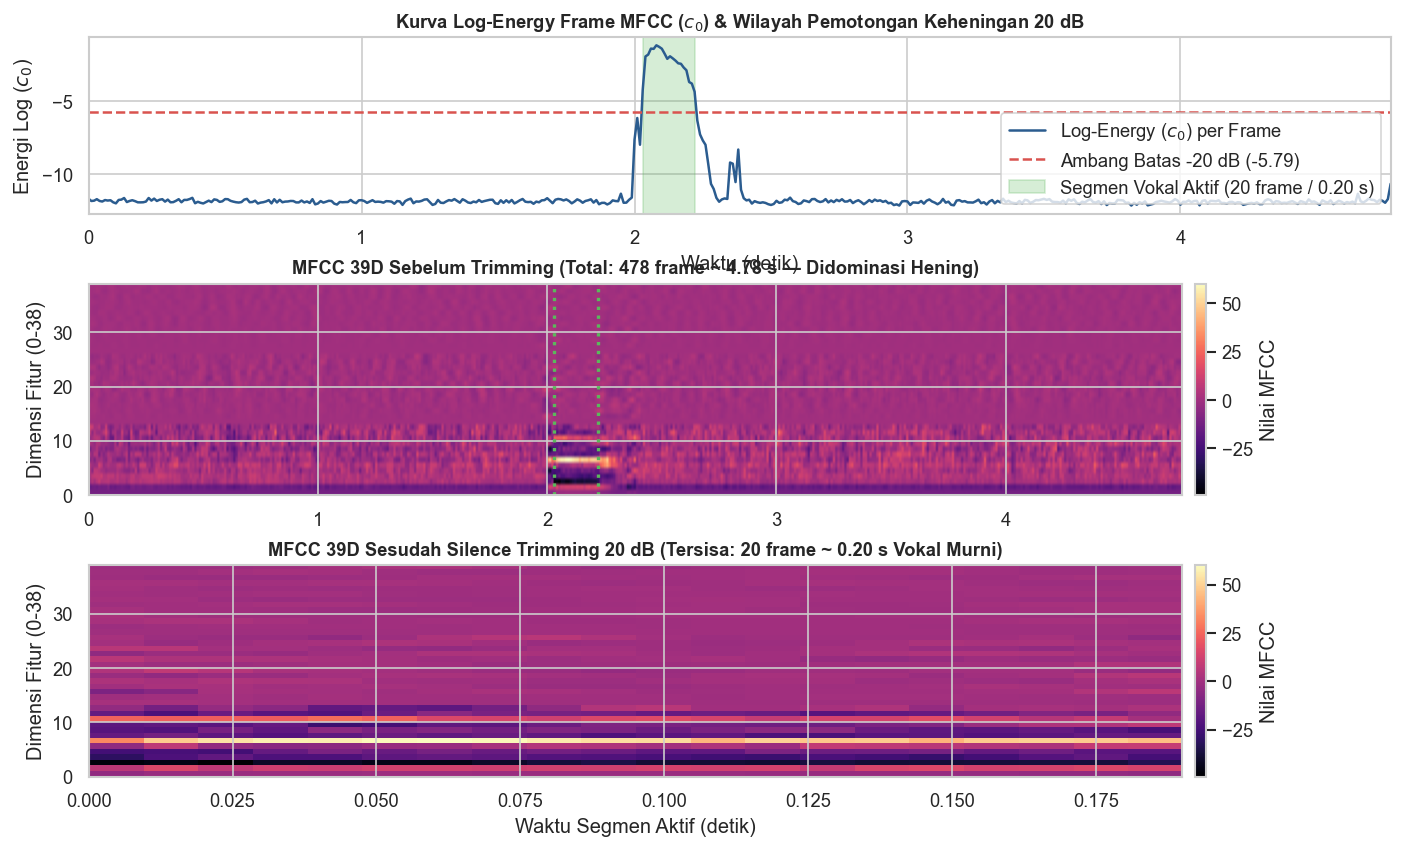

Hasil Trimming: 478 frame -> dipotong menjadi 20 frame (4.2% data aktif tersisa).


In [4]:
sample_path = "data/template/speaker01/speaker01_a_01.wav"
raw_features = process_audio_file(sample_path)
trimmed_features = trim_silence(raw_features, threshold_db=20)

energy_raw = raw_features[:, 0]
peak_energy = energy_raw.max()
threshold_val = peak_energy - 20 * np.log(10) / 10
active_indices = np.flatnonzero(energy_raw >= threshold_val)
start_idx, end_idx = active_indices[0], active_indices[-1]

fig = plt.figure(figsize=(14, 8))
gs = fig.add_gridspec(3, 2, height_ratios=[1, 1.2, 1.2], hspace=0.35, wspace=0.15)

ax_energy = fig.add_subplot(gs[0, :])
time_axis_raw = np.arange(len(raw_features)) * 0.01
ax_energy.plot(time_axis_raw, energy_raw, color="#2b5c8f", lw=1.5, label="Log-Energy ($c_0$) per Frame")
ax_energy.axhline(threshold_val, color="#d9534f", linestyle="--", lw=1.5,
                  label=f"Ambang Batas -20 dB ({threshold_val:.2f})")
ax_energy.axvspan(start_idx * 0.01, end_idx * 0.01, color="#5cb85c", alpha=0.25,
                  label=f"Segmen Vokal Aktif ({len(trimmed_features)} frame / {len(trimmed_features)*0.01:.2f} s)")
ax_energy.set_title("Kurva Log-Energy Frame MFCC ($c_0$) & Wilayah Pemotongan Keheningan 20 dB", fontsize=11, fontweight="bold")
ax_energy.set_xlabel("Waktu (detik)")
ax_energy.set_ylabel("Energi Log ($c_0$)")
ax_energy.legend(loc="lower right")
ax_energy.set_xlim(0, time_axis_raw[-1])

ax_raw = fig.add_subplot(gs[1, :])
im_raw = ax_raw.imshow(raw_features.T, aspect="auto", origin="lower", cmap="magma",
                       extent=[0, time_axis_raw[-1], 0, 39])
ax_raw.set_title(f"MFCC 39D Sebelum Trimming (Total: {len(raw_features)} frame ~ {len(raw_features)*0.01:.2f} s — Didominasi Hening)",
                 fontsize=11, fontweight="bold")
ax_raw.set_ylabel("Dimensi Fitur (0-38)")
ax_raw.axvline(start_idx * 0.01, color="#5cb85c", linestyle=":", lw=2)
ax_raw.axvline(end_idx * 0.01, color="#5cb85c", linestyle=":", lw=2)
fig.colorbar(im_raw, ax=ax_raw, orientation="vertical", pad=0.01, label="Nilai MFCC")

ax_trimmed = fig.add_subplot(gs[2, :])
time_axis_trimmed = np.arange(len(trimmed_features)) * 0.01
im_trimmed = ax_trimmed.imshow(trimmed_features.T, aspect="auto", origin="lower", cmap="magma",
                              extent=[0, time_axis_trimmed[-1], 0, 39])
ax_trimmed.set_title(f"MFCC 39D Sesudah Silence Trimming 20 dB (Tersisa: {len(trimmed_features)} frame ~ {len(trimmed_features)*0.01:.2f} s Vokal Murni)",
                     fontsize=11, fontweight="bold")
ax_trimmed.set_xlabel("Waktu Segmen Aktif (detik)")
ax_trimmed.set_ylabel("Dimensi Fitur (0-38)")
fig.colorbar(im_trimmed, ax=ax_trimmed, orientation="vertical", pad=0.01, label="Nilai MFCC")

plt.show()
print(f"Hasil Trimming: {len(raw_features)} frame -> dipotong menjadi {len(trimmed_features)} frame ({len(trimmed_features)/len(raw_features)*100:.1f}% data aktif tersisa).")


### 5. Fungsi Prediksi Langsung dari Berkas Audio WAV
Fungsi `predict_audio_file_integrated` disediakan untuk memproses path berkas audio `.wav` secara langsung. Ekstraksi MFCC, pemotongan hening, dan evaluasi skor oleh DTW dan Gaussian dijalankan secara otomatis.
- Pengujian dilakukan pada 1 berkas internal (`speaker01_a_02.wav`) dan 1 berkas eksternal (`external_g07_s01_i_01.wav`).
- Skor jarak DTW dan skor NLL Gaussian ditampilkan untuk kelima kelas vokal.

In [5]:
def predict_audio_file_integrated(wav_path, dtw_templates, gaussian_models, config=DEFAULT_CONFIG):
    path = Path(wav_path)
    if not path.exists():
        raise FileNotFoundError(f"File audio tidak ditemukan: {path}")
    
    features = process_audio_file(path, config=config)
    pred_dtw, costs_dtw = predict_dtw(features, dtw_templates)
    pred_gauss, costs_gauss = predict_gaussian(features, gaussian_models, trim=True)
    
    comparison_df = pd.DataFrame({
        "Vokal": list(VOWELS),
        "Cost DTW (Normalized)": [costs_dtw[v] for v in VOWELS],
        "Gaussian NLL (Per Frame)": [costs_gauss[v] for v in VOWELS]
    })
    
    return {
        "file_name": path.name,
        "total_frames_raw": len(features),
        "prediction_dtw": pred_dtw,
        "prediction_gaussian": pred_gauss,
        "scores_table": comparison_df
    }

dtw_models_loaded = load_templates("models/dtw_templates.npz")
gauss_models_loaded = load_models("models/gaussian_models.npz")

test_samples = [
    ("Closed Speaker Take 02 (/a/)", "data/test/closed_speakers/speaker01/speaker01_a_02.wav"),
    ("Open Speaker G07 (/i/)", "data/test/open_speakers/external_g07_s01/external_g07_s01_i_01.wav")
]

for label, wav_p in test_samples:
    res = predict_audio_file_integrated(wav_p, dtw_models_loaded, gauss_models_loaded)
    print(f"\n--- PENGUJIAN END-TO-END: {label} [{res['file_name']}] ---")
    print(f"Prediksi DTW      : /{res['prediction_dtw']}/")
    print(f"Prediksi Gaussian : /{res['prediction_gaussian']}/")
    display(res['scores_table'].style.format({
        "Cost DTW (Normalized)": "{:.2f}",
        "Gaussian NLL (Per Frame)": "{:.2f}"
    }).highlight_min(subset=["Cost DTW (Normalized)", "Gaussian NLL (Per Frame)"], color="#c3e6cb"))



--- PENGUJIAN END-TO-END: Closed Speaker Take 02 (/a/) [speaker01_a_02.wav] ---
Prediksi DTW      : /a/
Prediksi Gaussian : /a/


,Vokal,Cost DTW (Normalized),Gaussian NLL (Per Frame)
0,a,59.96,134.19
1,i,119.43,1226.08
2,u,102.69,781.06
3,e,104.84,1261.21
4,o,91.79,425.34



--- PENGUJIAN END-TO-END: Open Speaker G07 (/i/) [external_g07_s01_i_01.wav] ---
Prediksi DTW      : /i/
Prediksi Gaussian : /i/


,Vokal,Cost DTW (Normalized),Gaussian NLL (Per Frame)
0,a,93.51,659.30
1,i,47.05,211.32
2,u,77.12,385.34
3,e,57.56,318.53
4,o,90.98,619.14


### 6. Pembangunan Model & Verifikasi Numerik
Model DTW dan model Gaussian dibangun secara langsung dari 25 rekaman partisi `template` (Take 01).
- DTW: pencarian berkas medoid dan perataan sekuens per vokal.
- Gaussian: penggabungan seluruh frame aktif per vokal, dilanjutkan estimasi mean dan kovariansi penuh 39 x 39.
- Verifikasi dilakukan untuk memastikan kecocokan numerik dengan model tersimpan pada direktori `models/`.

In [6]:
template_records = load_dataset("template")
print(f"Partisi template dimuat: {len(template_records)} rekaman.")

built_dtw_templates = build_templates(template_records)
built_gauss_models = build_models(template_records, eps=1e-6, trim=True)

dtw_saved = load_templates("models/dtw_templates.npz")
gauss_saved = load_models("models/gaussian_models.npz")

dtw_match = all(np.allclose(built_dtw_templates[v], dtw_saved[v]) for v in VOWELS)
gauss_mean_match = all(np.allclose(built_gauss_models[v]["mean"], gauss_saved[v]["mean"]) for v in VOWELS)
gauss_cov_match = all(np.allclose(built_gauss_models[v]["cov"], gauss_saved[v]["cov"]) for v in VOWELS)

print(f"Verifikasi DTW Templates identik dengan models/dtw_templates.npz    : {dtw_match}")
print(f"Verifikasi Gaussian Mean identik dengan models/gaussian_models.npz   : {gauss_mean_match}")
print(f"Verifikasi Gaussian Cov identik dengan models/gaussian_models.npz    : {gauss_cov_match}")


Partisi template dimuat: 25 rekaman.


Verifikasi DTW Templates identik dengan models/dtw_templates.npz    : True
Verifikasi Gaussian Mean identik dengan models/gaussian_models.npz   : True
Verifikasi Gaussian Cov identik dengan models/gaussian_models.npz    : True


### 7. Tampilan Sidik Suara Template Rata-rata DTW
Heatmap MFCC 39 dimensi ditampilkan untuk template rata-rata kelima kelas vokal (/a/, /e/, /i/, /o/, /u/).
- Panjang frame setiap vokal bervariasi sesuai durasi rekaman medoid (/a/: 41, /e/: 72, /i/: 96, /o/: 74, /u/: 84 frame).
- Pola spektral khas tiap vokal terlihat dari distribusi kontur warna.

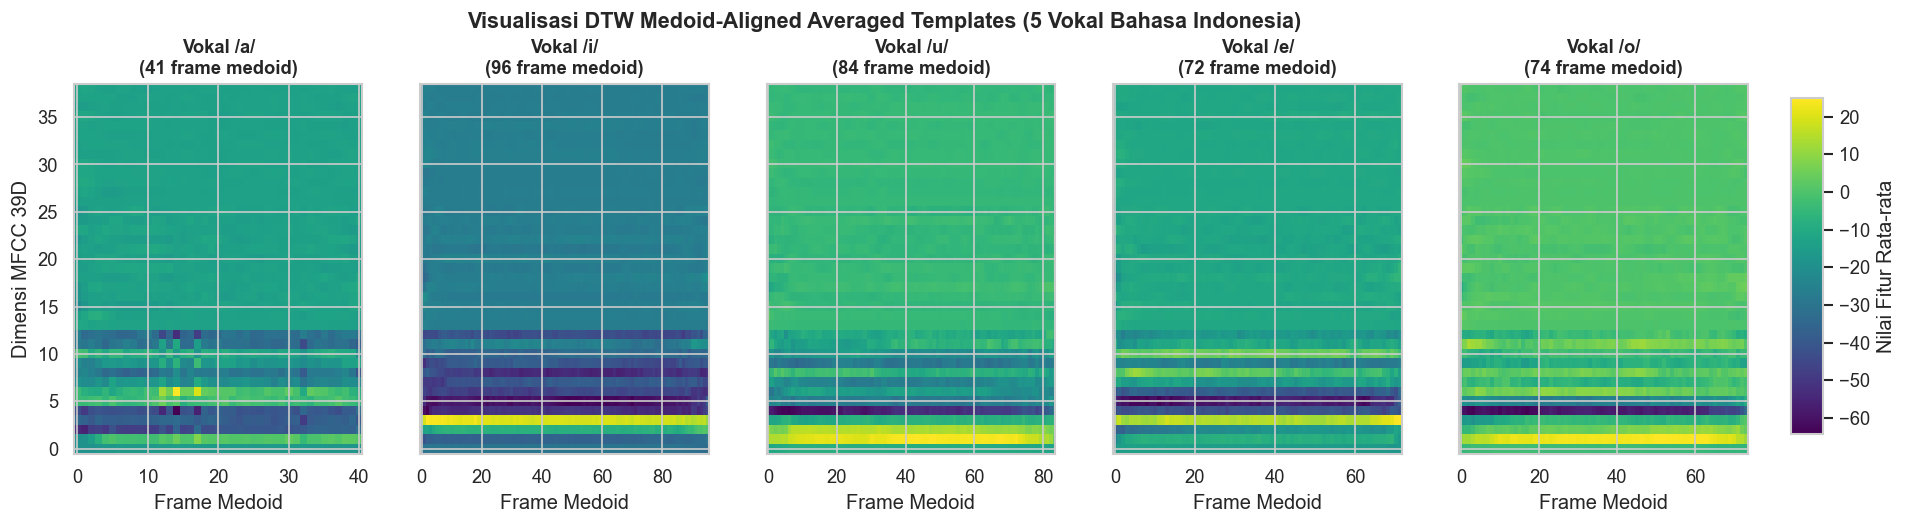

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4), sharey=True)

for ax, v in zip(axes, VOWELS):
    template_matrix = built_dtw_templates[v]
    im = ax.imshow(template_matrix.T, aspect="auto", origin="lower", cmap="viridis")
    ax.set_title(f"Vokal /{v}/\n({len(template_matrix)} frame medoid)", fontsize=11, fontweight="bold")
    ax.set_xlabel("Frame Medoid")
    if ax == axes[0]:
        ax.set_ylabel("Dimensi MFCC 39D")

cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
fig.colorbar(im, cax=cbar_ax, label="Nilai Fitur Rata-rata")
fig.suptitle("Visualisasi DTW Medoid-Aligned Averaged Templates (5 Vokal Bahasa Indonesia)",
             fontsize=13, fontweight="bold", y=1.03)
plt.show()


### 8. Visualisasi Jalur Penyejajaran DTW
Mekanisme penyejajaran sekuens oleh algoritma DTW diperlihatkan melalui dua perbandingan:
- Kiri (/a/ vs /a/): penyejajaran vokal yang sama menghasilkan jalur diagonal lurus dengan biaya rendah (~50.55).
- Kanan (/a/ vs /i/): penyejajaran vokal berbeda menghasilkan jalur berliku dengan biaya tinggi (~118.43).

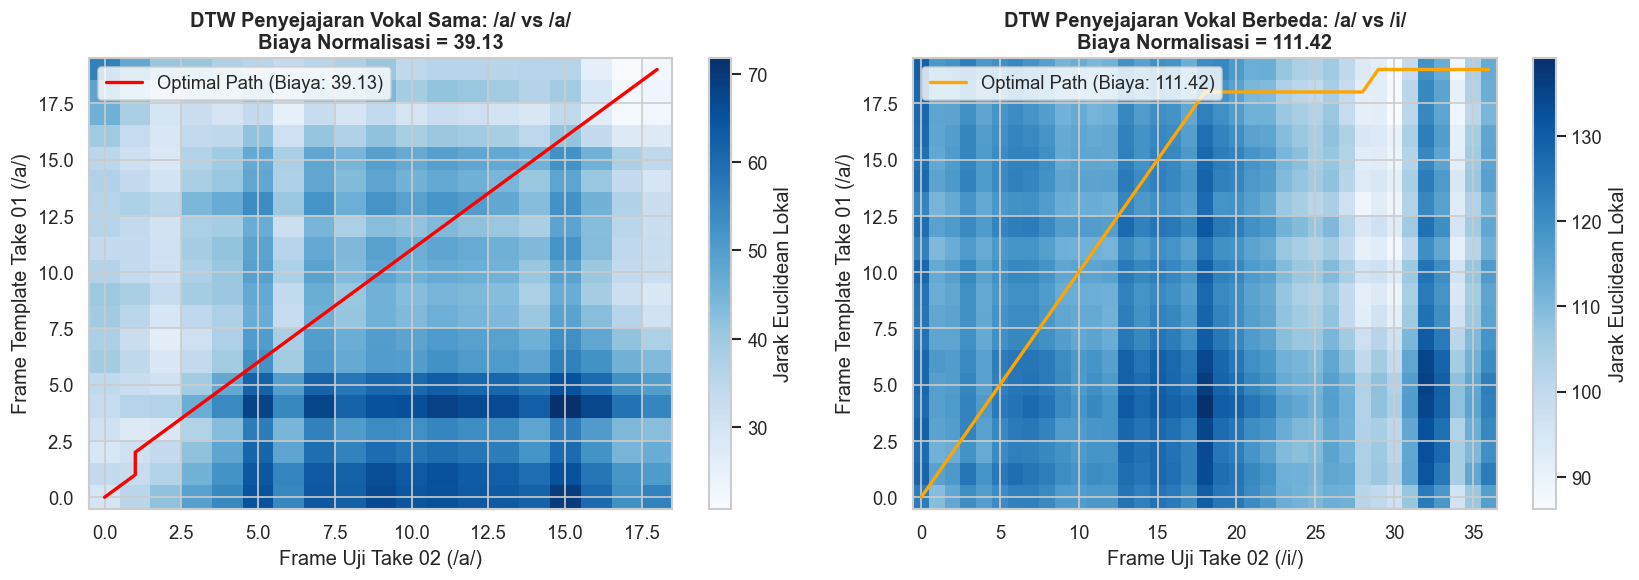

In [8]:
seq_a1 = trim_silence(load_dataset("template")[0]["features"])  # speaker01_a_01
seq_a2 = trim_silence(load_dataset("closed")[0]["features"])    # speaker01_a_02
seq_i2 = trim_silence(load_dataset("closed")[2]["features"])    # speaker01_i_02

cost_aa, path_aa = dtw(seq_a1, seq_a2)
cost_ai, path_ai = dtw(seq_a1, seq_i2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

dist_aa = np.linalg.norm(seq_a1[:, None, :] - seq_a2[None, :, :], axis=2)
im1 = ax1.imshow(dist_aa, origin="lower", cmap="Blues", aspect="auto")
path_aa_arr = np.array(path_aa)
ax1.plot(path_aa_arr[:, 1], path_aa_arr[:, 0], color="red", lw=2, label=f"Optimal Path (Biaya: {cost_aa:.2f})")
ax1.set_title(f"DTW Penyejajaran Vokal Sama: /a/ vs /a/\nBiaya Normalisasi = {cost_aa:.2f}", fontweight="bold")
ax1.set_xlabel("Frame Uji Take 02 (/a/)")
ax1.set_ylabel("Frame Template Take 01 (/a/)")
ax1.legend(loc="upper left")
fig.colorbar(im1, ax=ax1, label="Jarak Euclidean Lokal")

dist_ai = np.linalg.norm(seq_a1[:, None, :] - seq_i2[None, :, :], axis=2)
im2 = ax2.imshow(dist_ai, origin="lower", cmap="Blues", aspect="auto")
path_ai_arr = np.array(path_ai)
ax2.plot(path_ai_arr[:, 1], path_ai_arr[:, 0], color="orange", lw=2, label=f"Optimal Path (Biaya: {cost_ai:.2f})")
ax2.set_title(f"DTW Penyejajaran Vokal Berbeda: /a/ vs /i/\nBiaya Normalisasi = {cost_ai:.2f}", fontweight="bold")
ax2.set_xlabel("Frame Uji Take 02 (/i/)")
ax2.set_ylabel("Frame Template Take 01 (/a/)")
ax2.legend(loc="upper left")
fig.colorbar(im2, ax=ax2, label="Jarak Euclidean Lokal")

plt.tight_layout()
plt.show()


### 9. Visualisasi Parameter Model Gaussian
Dua parameter utama dari model Gaussian ditampilkan untuk kelima kelas vokal:
- Grafik kiri: profil nilai rata-rata 39 fitur. Fitur statis (0–12) memiliki daya pembeda tinggi, sedangkan fitur delta (13–38) bernilai mendekati nol.
- Heatmap kanan: matriks kovariansi yang telah diregulasi agar kestabilan numerik dekomposisi Cholesky terjaga.

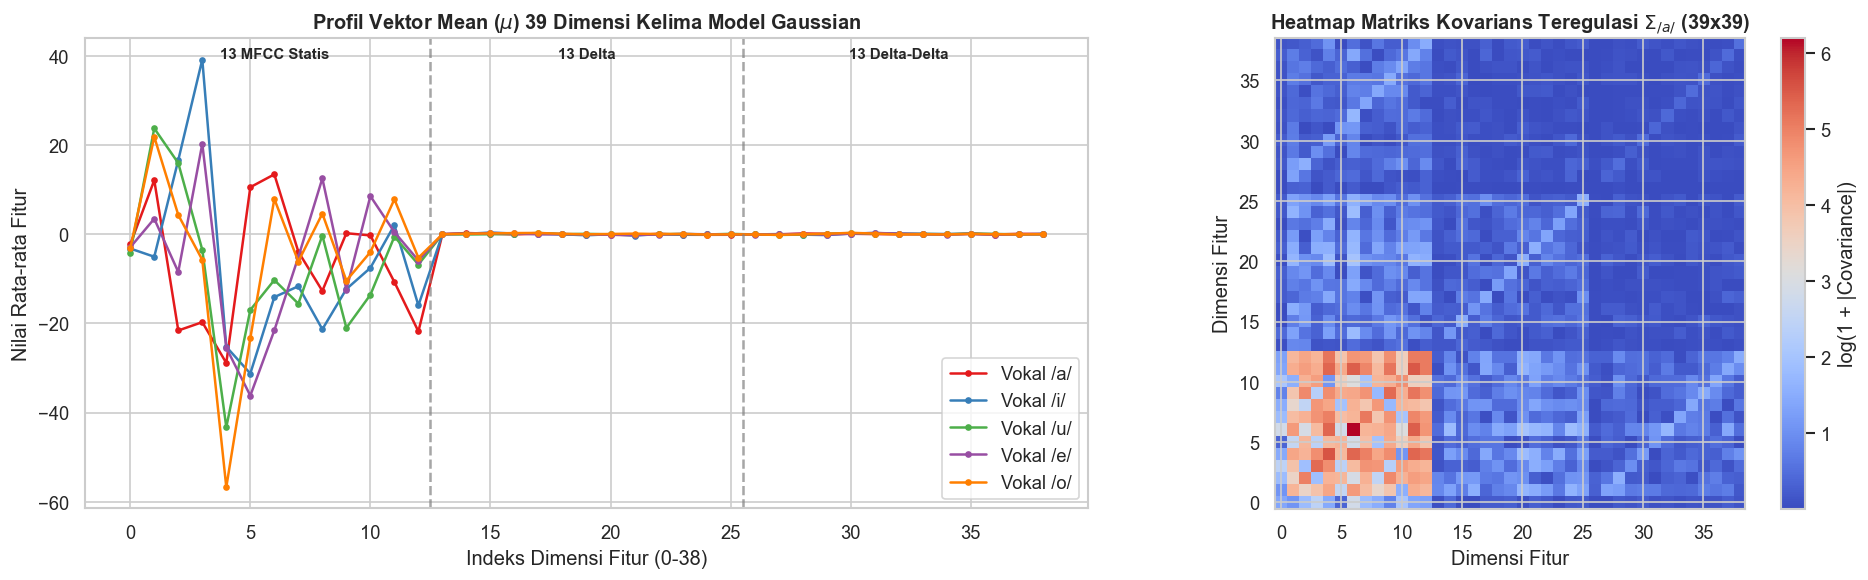

In [9]:
fig, (ax_mean, ax_cov) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1.4, 1]})

dim_axis = np.arange(39)
colors = {"a": "#e41a1c", "i": "#377eb8", "u": "#4daf4a", "e": "#984ea3", "o": "#ff7f00"}
for v in VOWELS:
    ax_mean.plot(dim_axis, built_gauss_models[v]["mean"], marker="o", markersize=3,
                 lw=1.5, color=colors[v], label=f"Vokal /{v}/")

ax_mean.axvline(12.5, color="gray", linestyle="--", alpha=0.7)
ax_mean.axvline(25.5, color="gray", linestyle="--", alpha=0.7)
ax_mean.text(6, ax_mean.get_ylim()[1]*0.9, "13 MFCC Statis", ha="center", fontsize=9, fontweight="bold")
ax_mean.text(19, ax_mean.get_ylim()[1]*0.9, "13 Delta", ha="center", fontsize=9, fontweight="bold")
ax_mean.text(32, ax_mean.get_ylim()[1]*0.9, "13 Delta-Delta", ha="center", fontsize=9, fontweight="bold")
ax_mean.set_title("Profil Vektor Mean ($\\mu$) 39 Dimensi Kelima Model Gaussian", fontweight="bold")
ax_mean.set_xlabel("Indeks Dimensi Fitur (0-38)")
ax_mean.set_ylabel("Nilai Rata-rata Fitur")
ax_mean.legend(loc="lower right")

cov_a = built_gauss_models["a"]["cov"]
im_cov = ax_cov.imshow(np.log1p(np.abs(cov_a)), cmap="coolwarm", origin="lower")
ax_cov.set_title("Heatmap Matriks Kovarians Teregulasi $\\Sigma_{/a/}$ (39x39)", fontweight="bold")
ax_cov.set_xlabel("Dimensi Fitur")
ax_cov.set_ylabel("Dimensi Fitur")
fig.colorbar(im_cov, ax=ax_cov, label="log(1 + |Covariance|)")

plt.tight_layout()
plt.show()


### 10. Eksekusi Pengujian Lengkap (260 Percobaan)
Pengujian otomatis dijalankan untuk kedua sistem pada 3 skenario: *Closed Recording* (25 berkas), *Closed Speakers* (25 berkas), dan *Open Speakers* (80 berkas). Total evaluasi berjumlah 260 prediksi.

In [10]:
experiment_rows = ev.run_experiments("features")
print(f"Done. Total baris prediksi: {len(experiment_rows)}")

predictions_df = pd.DataFrame(experiment_rows)
display(predictions_df.head(6))


Done. Total baris prediksi: 260


,system,scenario,speaker,true,pred,correct,file,cost_a,cost_i,cost_u,cost_e,cost_o
0,dtw,closed_recording,speaker01,a,a,1,speaker01_a_01.wav,50.547694,118.428925,96.071128,101.785086,87.192492
1,gaussian,closed_recording,speaker01,a,a,1,speaker01_a_01.wav,80.757995,1089.858091,749.583944,1195.536751,368.983835
2,dtw,closed_recording,speaker01,e,e,1,speaker01_e_01.wav,99.489062,59.002706,91.506825,46.390418,89.379330
3,gaussian,closed_recording,speaker01,e,e,1,speaker01_e_01.wav,878.298060,404.260972,402.933796,79.057517,470.239662
4,dtw,closed_recording,speaker01,i,i,1,speaker01_i_01.wav,98.137925,34.259952,79.232685,67.165379,90.307026
5,gaussian,closed_recording,speaker01,i,i,1,speaker01_i_01.wav,839.545409,80.460565,613.046073,322.836366,777.261673


### 11. Tabel 0: Ringkasan Akurasi Sistem
Perbandingan akurasi DTW Template dan Model Gaussian disajikan pada ketiga skenario evaluasi. Kolom rata-rata memberi bobot yang sama pada setiap skenario; akurasi agregat dihitung dari seluruh prediksi per sistem.

In [11]:
h0, b0 = ev.summary_table(experiment_rows)
table0_df = pd.DataFrame(b0, columns=h0)

display(table0_df.style.format({
    "Closed Recording": "{:.1f}%",
    "Closed Speakers": "{:.1f}%",
    "Open Speakers": "{:.1f}%",
    "Rata-rata": "{:.2f}%"
}))

aggregate_rows = [{
    "Sistem": ev.SYSTEM_LABEL[system],
    "Benar": sum(r["correct"] for r in experiment_rows if r["system"] == system),
    "Total": sum(r["system"] == system for r in experiment_rows),
    "Akurasi agregat (%)": ev.accuracy(experiment_rows, system=system),
} for system in ev.SYSTEMS]
display(pd.DataFrame(aggregate_rows).style.format({"Akurasi agregat (%)": "{:.2f}%"}))


,Sistem,Closed Recording,Closed Speakers,Open Speakers,Rata-rata
0,DTW Template,96.0%,92.0%,86.2%,91.42%
1,Model Gaussian,100.0%,100.0%,81.2%,93.75%


,Sistem,Benar,Total,Akurasi agregat (%)
0,DTW Template,116,130,89.23%
1,Model Gaussian,115,130,88.46%


### 12. Tabel 1: Akurasi untuk Setiap Fonem Vokal
Rincian persentase akurasi disajikan untuk masing-masing fonem vokal (/a/, /i/, /u/, /e/, /o/) pada setiap sistem dan skenario.

In [12]:
h1, b1 = ev.per_vowel_table(experiment_rows)
table1_df = pd.DataFrame(b1, columns=h1)

numeric_cols_t1 = [c for c in table1_df.columns if c != "Vowel"]
format_dict_t1 = {c: "{:.1f}%" for c in numeric_cols_t1}

display(table1_df.style.format(format_dict_t1))


,Vowel,DTW Closed Recording,DTW Closed Speakers,DTW Open Speakers,Gaussian Closed Recording,Gaussian Closed Speakers,Gaussian Open Speakers
0,a,100.0%,100.0%,93.8%,100.0%,100.0%,100.0%
1,i,100.0%,100.0%,93.8%,100.0%,100.0%,81.2%
2,u,100.0%,100.0%,100.0%,100.0%,100.0%,87.5%
3,e,100.0%,80.0%,93.8%,100.0%,100.0%,56.2%
4,o,80.0%,80.0%,50.0%,100.0%,100.0%,81.2%
5,Average Accuracy,96.0%,92.0%,86.2%,100.0%,100.0%,81.2%


### 13. Tabel 2: Akurasi Pembicara Internal (Closed Experiments)
Hasil akurasi pengujian internal disajikan untuk kelima pembicara (`speaker01` sampai `speaker05`).
- Seluruh pembicara pria memperoleh akurasi 100%.
- Penurunan akurasi pada sistem DTW terjadi pada `speaker02` akibat perbedaan karakteristik frekuensi fundamental pembicara wanita terhadap template.

In [13]:
h2, b2 = ev.per_speaker_table(experiment_rows, ("closed_recording", "closed_speakers"), "Speaker")
table2_df = pd.DataFrame(b2, columns=h2)

numeric_cols_t2 = [c for c in table2_df.columns if c != "Speaker"]
format_dict_t2 = {c: "{:.1f}%" for c in numeric_cols_t2}

display(table2_df.style.format(format_dict_t2))


,Speaker,DTW Closed Recording,Gaussian Closed Recording,DTW Closed Speakers,Gaussian Closed Speakers,Average
0,speaker01,100.0%,100.0%,100.0%,100.0%,100.0%
1,speaker02,80.0%,100.0%,60.0%,100.0%,85.0%
2,speaker03,100.0%,100.0%,100.0%,100.0%,100.0%
3,speaker04,100.0%,100.0%,100.0%,100.0%,100.0%
4,speaker05,100.0%,100.0%,100.0%,100.0%,100.0%
5,Average,96.0%,100.0%,92.0%,100.0%,97.0%


### 14. Tabel 3: Akurasi Pembicara Eksternal (Open Experiments)
Hasil akurasi disajikan untuk 16 pembicara eksternal dari G03/Kel3, G04, G07, dan G09 yang tidak disertakan dalam data pelatihan.
- Pengujian ini mengukur kemampuan generalisasi model terhadap pembicara baru secara independen (*speaker-independent*).

In [14]:
h3, b3 = ev.per_speaker_table(experiment_rows, ("open_speakers",), "Speaker (open)")
table3_df = pd.DataFrame(b3, columns=h3)

numeric_cols_t3 = [c for c in table3_df.columns if c != "Speaker (open)"]
format_dict_t3 = {c: "{:.1f}%" for c in numeric_cols_t3}

display(table3_df.style.format(format_dict_t3))


,Speaker (open),DTW Open Speakers,Gaussian Open Speakers,Average
0,external_g03_s01,100.0%,100.0%,100.0%
1,external_g03_s02,60.0%,80.0%,70.0%
2,external_g03_s03,60.0%,80.0%,70.0%
3,external_g03_s05,100.0%,100.0%,100.0%
4,external_g04_s03,80.0%,60.0%,70.0%
5,external_g04_s04,60.0%,60.0%,60.0%
6,external_g07_s01,80.0%,80.0%,80.0%
7,external_g07_s02,80.0%,60.0%,70.0%
8,external_g07_s03,100.0%,100.0%,100.0%
9,external_g07_s04,100.0%,60.0%,80.0%


### 15. Matriks Konfusi (Pola Klasifikasi Sistem)
Distribusi prediksi ditampilkan melalui matriks konfusi pada 6 skenario pengujian.
- Nilai pada diagonal utama menunjukkan frekuensi klasifikasi yang tepat.
- Nilai di luar diagonal utama memetakan sebaran konfusi antar-vokal.

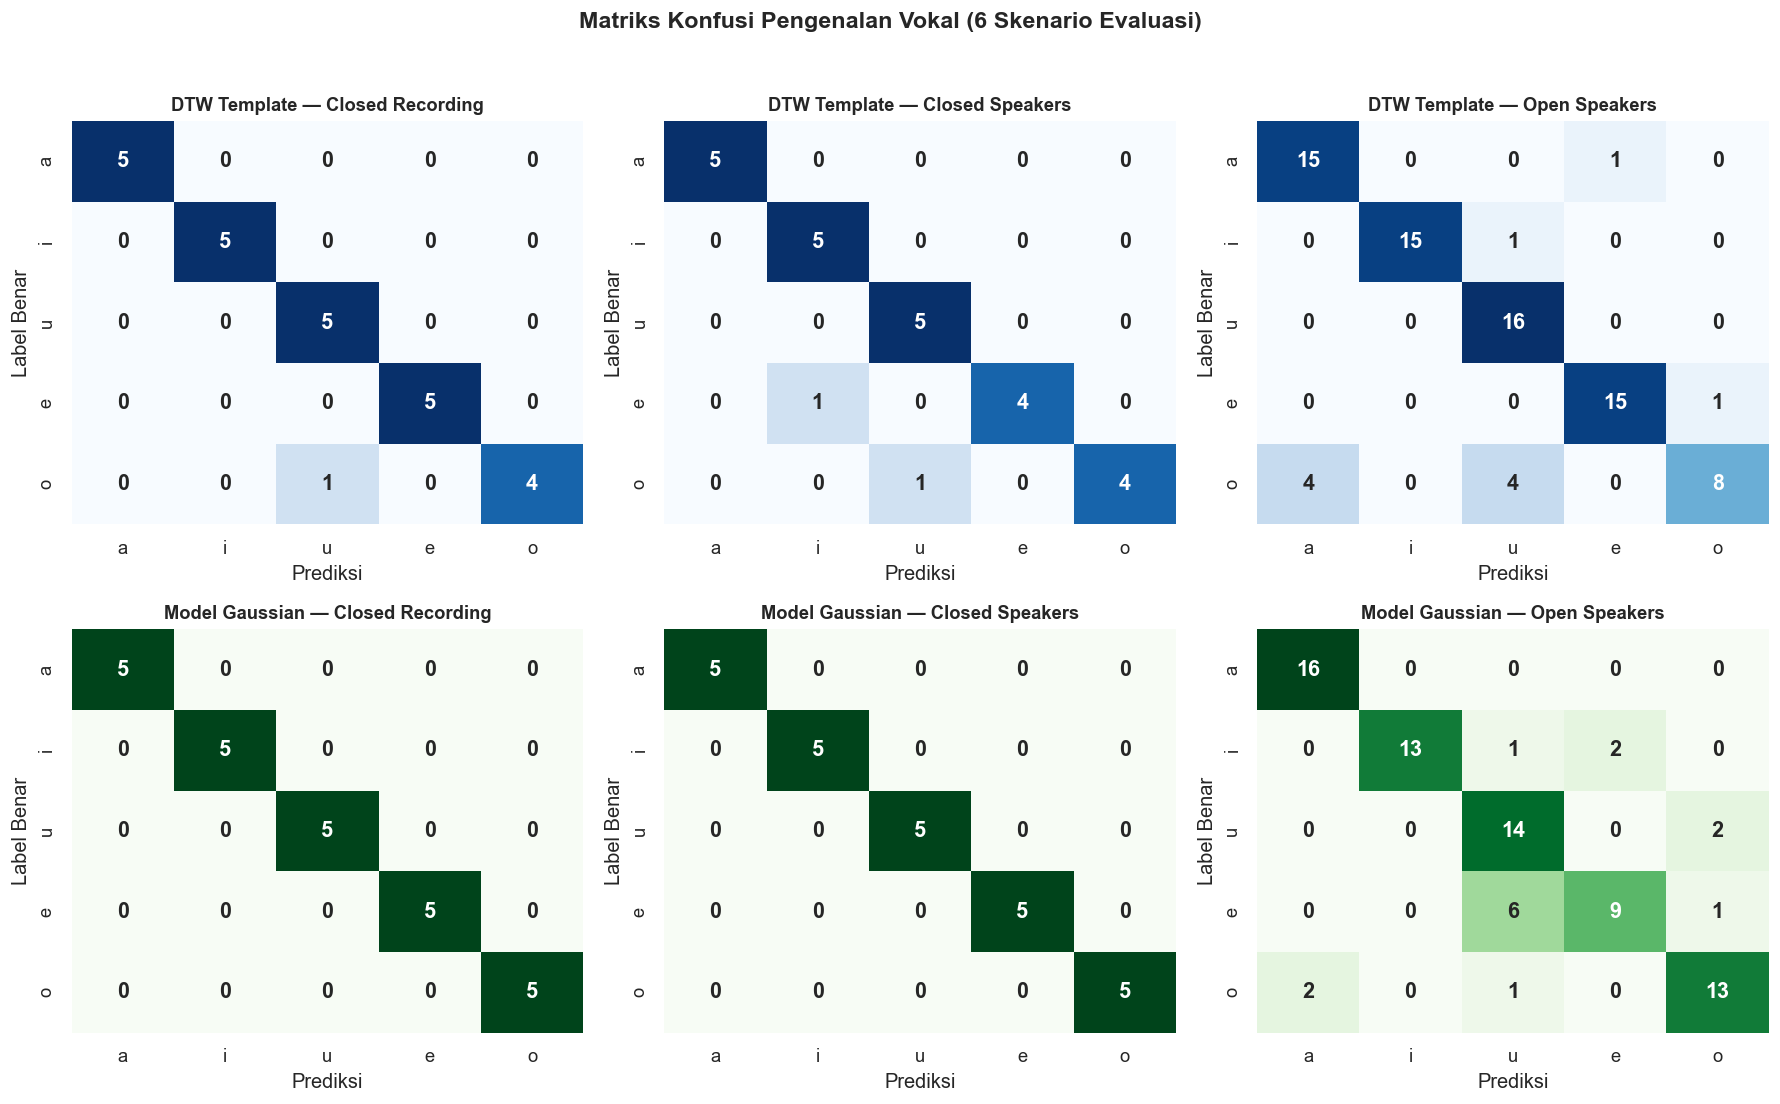

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for row_idx, sys_name in enumerate(["dtw", "gaussian"]):
    sys_title = "DTW Template" if sys_name == "dtw" else "Model Gaussian"
    for col_idx, sc_name in enumerate(["closed_recording", "closed_speakers", "open_speakers"]):
        ax = axes[row_idx, col_idx]
        sc_title = ev.SCENARIO_LABEL[sc_name]
        cm = ev.confusion_matrix(experiment_rows, sys_name, sc_name)
        
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues" if sys_name == "dtw" else "Greens",
                    cbar=False, ax=ax, xticklabels=VOWELS, yticklabels=VOWELS,
                    annot_kws={"size": 13, "weight": "bold"})
        ax.set_title(f"{sys_title} — {sc_title}", fontsize=11, fontweight="bold")
        ax.set_xlabel("Prediksi")
        ax.set_ylabel("Label Benar")

plt.suptitle("Matriks Konfusi Pengenalan Vokal (6 Skenario Evaluasi)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


### 16. Grafik Batang Perbandingan Akurasi
Visualisasi perbandingan performa disajikan melalui diagram batang berdasarkan skenario evaluasi dan kelas fonem vokal.

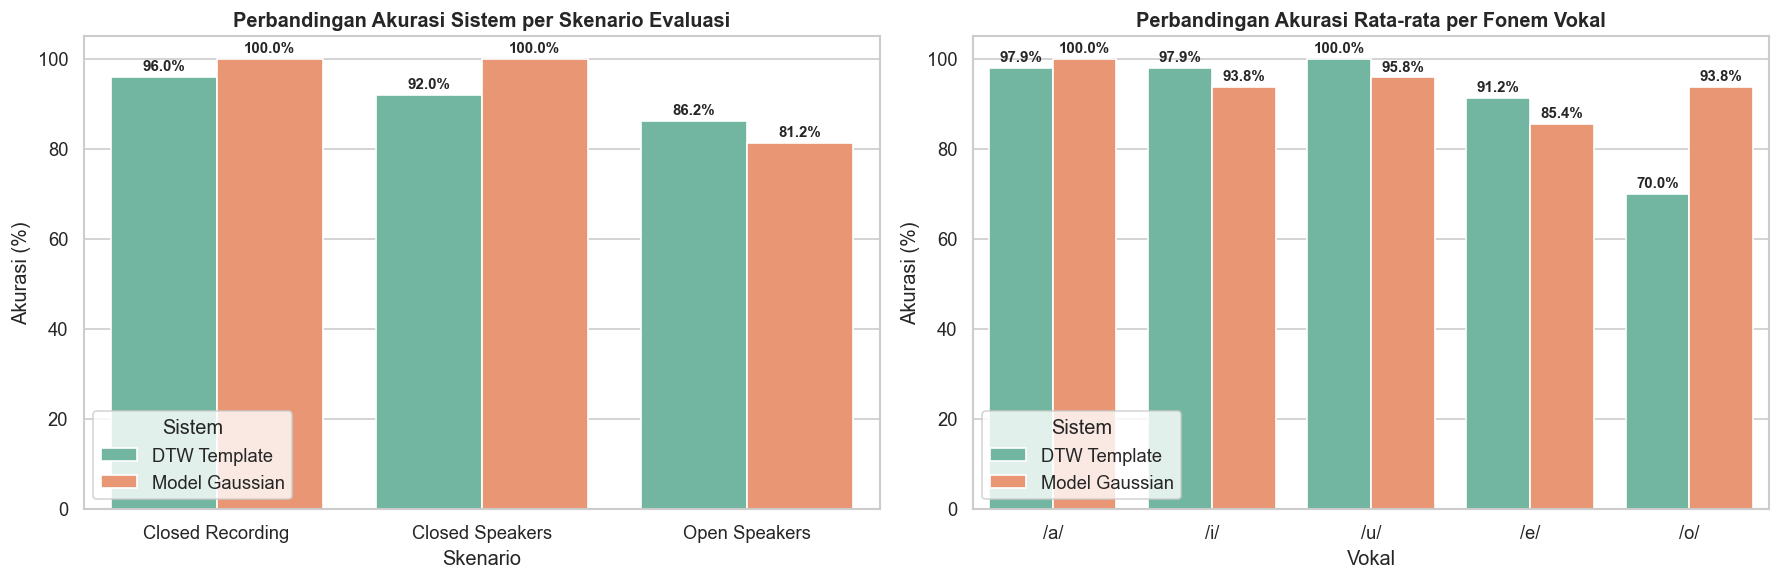

In [16]:
fig, (ax_sc, ax_vw) = plt.subplots(1, 2, figsize=(15, 5))

df_plot_sc = table0_df.melt(id_vars=["Sistem"], value_vars=["Closed Recording", "Closed Speakers", "Open Speakers"],
                            var_name="Skenario", value_name="Akurasi")
sns.barplot(data=df_plot_sc, x="Skenario", y="Akurasi", hue="Sistem", ax=ax_sc, palette="Set2")
ax_sc.set_title("Perbandingan Akurasi Sistem per Skenario Evaluasi", fontweight="bold")
ax_sc.set_ylabel("Akurasi (%)")
ax_sc.set_ylim(0, 105)
for p in ax_sc.patches:
    height = p.get_height()
    if height > 0:
        ax_sc.annotate(f"{height:.1f}%", (p.get_x() + p.get_width() / 2., height + 0.8),
                       ha='center', va='bottom', fontsize=9, fontweight="bold")

vowel_rows = table1_df[table1_df["Vowel"].isin(list(VOWELS))].copy()
vowel_scores = []
for _, row in vowel_rows.iterrows():
    v = row["Vowel"]
    dtw_acc = np.mean([row["DTW Closed Recording"], row["DTW Closed Speakers"], row["DTW Open Speakers"]])
    gauss_acc = np.mean([row["Gaussian Closed Recording"], row["Gaussian Closed Speakers"], row["Gaussian Open Speakers"]])
    vowel_scores.append({"Vokal": f"/{v}/", "DTW Template": dtw_acc, "Model Gaussian": gauss_acc})

df_plot_vw = pd.DataFrame(vowel_scores).melt(id_vars=["Vokal"], var_name="Sistem", value_name="Akurasi")
sns.barplot(data=df_plot_vw, x="Vokal", y="Akurasi", hue="Sistem", ax=ax_vw, palette="Set2")
ax_vw.set_title("Perbandingan Akurasi Rata-rata per Fonem Vokal", fontweight="bold")
ax_vw.set_ylabel("Akurasi (%)")
ax_vw.set_ylim(0, 105)
for p in ax_vw.patches:
    height = p.get_height()
    if height > 0:
        ax_vw.annotate(f"{height:.1f}%", (p.get_x() + p.get_width() / 2., height + 0.8),
                       ha='center', va='bottom', fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()


### 17. Daftar Kesalahan Klasifikasi
Kasus salah klasifikasi ditampilkan beserta sistem, skenario, pembicara, label asli, dan hasil prediksi.
Dari 260 prediksi, terdapat 29 kesalahan: 14 pada DTW dan 15 pada Gaussian.

In [17]:
error_records = ev.error_list(experiment_rows)
errors_df = pd.DataFrame([{
    "No": i + 1,
    "Sistem": ev.SYSTEM_LABEL[r["system"]],
    "Skenario": ev.SCENARIO_LABEL[r["scenario"]],
    "Speaker": r["speaker"],
    "Label Asli": f"/{r['true']}/",
    "Prediksi": f"/{r['pred']}/",
    "File Audio": r["file"]
} for i, r in enumerate(error_records)])

display(errors_df)


,No,Sistem,Skenario,Speaker,Label Asli,Prediksi,File Audio
0,1,DTW Template,Closed Recording,speaker02,/o/,/u/,speaker02_o_01.wav
1,2,DTW Template,Closed Speakers,speaker02,/e/,/i/,speaker02_e_02.wav
2,3,DTW Template,Closed Speakers,speaker02,/o/,/u/,speaker02_o_02.wav
3,4,DTW Template,Open Speakers,external_g03_s02,/a/,/e/,external_g03_s02_a_01.wav
4,5,DTW Template,Open Speakers,external_g03_s02,/o/,/u/,external_g03_s02_o_01.wav
5,6,Model Gaussian,Open Speakers,external_g03_s02,/o/,/u/,external_g03_s02_o_01.wav
6,7,Model Gaussian,Open Speakers,external_g03_s03,/e/,/u/,external_g03_s03_e_01.wav
7,8,DTW Template,Open Speakers,external_g03_s03,/i/,/u/,external_g03_s03_i_01.wav
8,9,DTW Template,Open Speakers,external_g03_s03,/o/,/u/,external_g03_s03_o_01.wav
9,10,Model Gaussian,Open Speakers,external_g04_s03,/e/,/u/,external_g04_s03_e_01.wav


### 18. Pengukuran Waktu Inferensi (Latensi Komputasi)
Waktu inferensi diukur pada fitur 25 rekaman closed-speaker menggunakan model DTW dan Gaussian.
- Rata-rata DTW: 10.75 ms per berkas.
- Rata-rata Gaussian: 1.24 ms per berkas.
- Rasio latensi DTW terhadap Gaussian: 8.7 kali.

,Metrik Komputasi,DTW Template (Dynamic Programming),Model Gaussian (Cholesky Solve)
0,Rata-rata Latensi per File,10.75 ms,1.24 ms
1,Standar Deviasi,4.46 ms,0.41 ms
2,Latensi Tercepat,4.30 ms,0.56 ms
3,Latensi Terlambat,21.81 ms,2.56 ms
4,Throughput (File / Detik),93.0 files/s,806.6 files/s


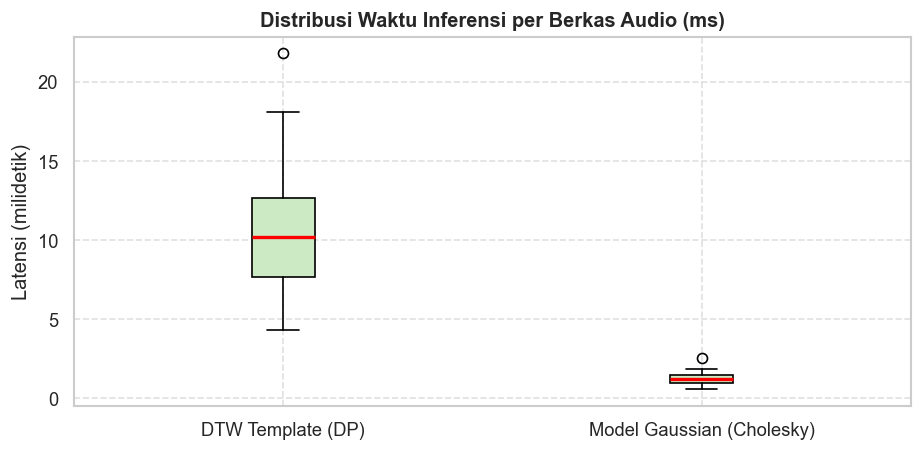

Hasil Benchmark: Model Gaussian rata-rata 8.7x lebih cepat daripada DTW.


In [18]:
test_records = load_dataset("closed")
dtw_models_b = load_templates("models/dtw_templates.npz")
gauss_models_b = load_models("models/gaussian_models.npz")

latencies_dtw = []
latencies_gauss = []

for item in test_records:
    feat = item["features"]
    
    t0 = time.perf_counter()
    predict_dtw(feat, dtw_models_b)
    t1 = time.perf_counter()
    latencies_dtw.append((t1 - t0) * 1000)
    
    t2 = time.perf_counter()
    predict_gaussian(feat, gauss_models_b, trim=True)
    t3 = time.perf_counter()
    latencies_gauss.append((t3 - t2) * 1000)

latency_df = pd.DataFrame({
    "Metrik Komputasi": ["Rata-rata Latensi per File", "Standar Deviasi", "Latensi Tercepat", "Latensi Terlambat", "Throughput (File / Detik)"],
    "DTW Template (Dynamic Programming)": [
        f"{np.mean(latencies_dtw):.2f} ms",
        f"{np.std(latencies_dtw):.2f} ms",
        f"{np.min(latencies_dtw):.2f} ms",
        f"{np.max(latencies_dtw):.2f} ms",
        f"{1000 / np.mean(latencies_dtw):.1f} files/s"
    ],
    "Model Gaussian (Cholesky Solve)": [
        f"{np.mean(latencies_gauss):.2f} ms",
        f"{np.std(latencies_gauss):.2f} ms",
        f"{np.min(latencies_gauss):.2f} ms",
        f"{np.max(latencies_gauss):.2f} ms",
        f"{1000 / np.mean(latencies_gauss):.1f} files/s"
    ]
})

display(latency_df)

plt.figure(figsize=(9, 4))
plt.boxplot([latencies_dtw, latencies_gauss], tick_labels=["DTW Template (DP)", "Model Gaussian (Cholesky)"], patch_artist=True,
            boxprops=dict(facecolor="#ccebc5"), medianprops=dict(color="red", lw=2))
plt.title("Distribusi Waktu Inferensi per Berkas Audio (ms)", fontweight="bold")
plt.ylabel("Latensi (milidetik)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

ratio_speed = np.mean(latencies_dtw) / np.mean(latencies_gauss)
print(f"Hasil Benchmark: Model Gaussian rata-rata {ratio_speed:.1f}x lebih cepat daripada DTW.")


### 19. Kesimpulan & Rekomendasi Integrasi

Evaluasi mencakup 130 rekaman per sistem: 25 closed-recording, 25 closed-speaker, dan 80 open-speaker dari 16 pembicara eksternal. Kedua sistem menghasilkan 260 prediksi.

#### 1. Perbandingan Akurasi Sistem (Tabel 0)
- **DTW Template**: closed-recording 96.0%, closed-speaker 92.0%, dan open-speaker 86.2%. Rata-rata tiga skenario 91.42%; akurasi agregat 89.23% (116/130 prediksi).
- **Model Gaussian**: closed-recording 100.0%, closed-speaker 100.0%, dan open-speaker 81.2%. Rata-rata tiga skenario 93.75%; akurasi agregat 88.46% (115/130 prediksi).

Rata-rata skenario memberi bobot sama pada setiap skenario. Akurasi agregat memberi bobot sama pada setiap rekaman, sehingga partisi open yang lebih besar memiliki pengaruh lebih besar.

#### 2. Kesalahan Pengenalan Vokal (Tabel 1)
Terdapat 29 kesalahan: 14 pada DTW dan 15 pada Gaussian.
- DTW Template: pasangan kesalahan terbanyak adalah /o/ menjadi /u/, masing-masing 6 kali.
- Model Gaussian: pasangan kesalahan terbanyak adalah /e/ menjadi /u/, masing-masing 6 kali.

#### 3. Akurasi Pembicara Eksternal (Tabel 3)
- Rata-rata akurasi dua sistem tertinggi: 100.0% pada `external_g03_s01`, `external_g03_s05`, `external_g07_s03`, `external_g09_s02`, `external_g09_s04`.
- Rata-rata akurasi dua sistem terendah: 60.0% pada `external_g04_s04`.

#### 4. Waktu Inferensi
- Rata-rata latensi: DTW 10.75 ms per berkas dan Gaussian 1.24 ms per berkas pada partisi closed-speaker.
- Rasio rata-rata latensi DTW terhadap Gaussian: 8.7 kali.